<a href="https://colab.research.google.com/github/Abdulrahman-Alnakshabandi/Project-1/blob/main/Project_1_G5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ENDG 310 Project 1 - Group 5**
**Authors:** Chenrong Li, Abdulrahman Alnakshabandi, Michael Klimachevski, James Symonds

# **AI use:**

Claude was used to help read the assignment and assign scope of work to each member of the group.

Claude was used to write the citation and summarize what was done in Michael's cell - Prompt: Could you cite and summarize what I did in the cell, please make as minimal changes as possible.

Claude also explained and suggested parts of the averaging loops and helped debug.

Chat GPT - Codex - was used in Abdulrahman's section in debugging the code, and refining the annotationsa and comments - Prompt: Read and understand this code. Check the following error and find where it is, and suggest comments to help my group members understand the code. Do not directly make any changes to the code.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Locate the CSV in the data folder inside the same project directory as this script.
# This works on any computer when the project's folder structure stays the same.
PROJECT_DIR = "/content/drive/MyDrive/ENDG_310_G5_2026/Project_01"
IBTRACS_FILE = PROJECT_DIR + "/data/ibtracs.NA.list.v04r01 (1).csv"
SHIPS_DIR = PROJECT_DIR + "/data/ships_atlantic_7days.csv"

Mounted at /content/drive


# Chenrong (Max)


In [ ]:
#Use pathlib could make the process of reading csv/xlsx file faster
from pathlib import Path

START_YEAR = 1980
END_YEAR = 2025
MINIMUM_ROWS = 1500 #make more than 500 rows to meet class requirements

#main part1: create the main function
def create_plot(csv_file=IBTRACS_FILE, show=True):
    csv_file = Path(csv_file)

#read only 6 columns
    data = pd.read_csv(
        csv_file,
        skiprows=[1],
        usecols=["SID", "SEASON", "NAME", "ISO_TIME", "USA_WIND", "USA_PRES"], #compare
        low_memory=False, #let pandas use more memory to identify the data type (regularly was true)
    )

    data = data[data["SEASON"].between(START_YEAR, END_YEAR)].copy()

    #main part2: clean the data
    # Blank measurements in the original CSV become missing values (NaN).
    data["USA_WIND"] = pd.to_numeric(data["USA_WIND"], errors="coerce")
    data["USA_PRES"] = pd.to_numeric(data["USA_PRES"], errors="coerce")
    data["ISO_TIME"] = pd.to_datetime(data["ISO_TIME"], errors="coerce")

    data = data.dropna(subset=["USA_WIND", "USA_PRES", "ISO_TIME"])
    data = data[(data["USA_WIND"] > 0) & (data["USA_PRES"] > 0)].copy()

    # Retain the standard 00, 06, 12, and 18 UTC observations only.
    data = data[
        data["ISO_TIME"].dt.hour.isin([0, 6, 12, 18])
        & (data["ISO_TIME"].dt.minute == 0)
    ].copy()

    #count if there is more than 1500 rows or not after reading the file, and cleaning the NaN
    if len(data) < MINIMUM_ROWS:
        raise ValueError(
            "Only " + str(len(data)) + " valid rows are available, but at least "
            + str(MINIMUM_ROWS) + " are required. "
            "Try widening START_YEAR and END_YEAR."
        )

    #main part3: calculate avg pressure
    data["wind_bin"] = (data["USA_WIND"] // 10 * 10).astype(int) #astype convert the data to integers
    averages = data.groupby("wind_bin", as_index=False).agg(     #as_index: used to keep wind_bin normal
        mean_wind=("USA_WIND", "mean"),              #agg: calculates summarized statistics for each group
        mean_pressure=("USA_PRES", "mean"),
    )

    #main part4: identify every cate.5 cyclones
    # Category 5 begins at 137 knots
    category_5 = data[data["USA_WIND"] >= 137]

    #main part5: identify the highest wind speeds
    maximum_wind = data["USA_WIND"].max()
    strongest = data[data["USA_WIND"] == maximum_wind]
    strongest_storms = strongest.drop_duplicates(subset="SID") #removing repeated data for the same cyclone

    fig, ax = plt.subplots(figsize=(12, 7.5)) #figure, axes

    #main part6: plot the graph
    #all usable observations.
    ax.scatter(              #axes, scatter graph
        data["USA_WIND"],
        data["USA_PRES"],
        color="gray",
        s=13,             #Area of the graph
        alpha=0.18,          #82 percent transparency
        edgecolors="none",
        label="6-hourly cyclone observations",
        zorder=2,           #drawing layer
    )

    #Category 5 measurements, highlight
    ax.scatter(
        category_5["USA_WIND"],
        category_5["USA_PRES"],
        color="royalblue",
        s=38,
        alpha=0.8,
        edgecolors="white",
        linewidths=0.4,
        label="Category 5 observations (137+ knots)",
        zorder=3,   #drawing above the gray layer
    )

    #average pressure at each 10-knot interval.
    ax.plot(
        averages["mean_wind"],
        averages["mean_pressure"],
        color="darkorange",
        linewidth=3.5,
        marker="o",
        markersize=6,
        label="Average central pressure (10-knot intervals)",
        zorder=4,
    )

    #the most intense wind-speed observations.
    ax.scatter(
        strongest_storms["USA_WIND"],
        strongest_storms["USA_PRES"],
        color="crimson",        #red marker
        marker="*",          #star-shaped point
        s=260,
        edgecolors="white",
        linewidths=0.8,
        label="Highest recorded wind speed in selected years",
        zorder=5,
    )

    #strongest
    for i, storm in enumerate(strongest_storms.itertuples(index=False)):
        offset = (18, -30) if i % 2 == 0 else (18, 30)
        label = str(storm.NAME).title() + " (" + str(storm.SEASON) + ")"
        ax.annotate(          #axes, specific point
            label,
            xy=(storm.USA_WIND, storm.USA_PRES),
            xytext=offset,
            textcoords="offset points",
            color="crimson",
            fontsize=9,
            weight="bold",
            arrowprops={"arrowstyle": "-", "color": "crimson", "lw": 1},
            zorder=6,
        )

    #threshold
    ax.axvline(     #axvline: axes.vertical.line(to show the 137 knots wind speed on the graph)
        x=137,
        color="royalblue",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        label="Category 5 wind-speed threshold (137 knots)",
    )

    ax.set_title(
        "North Atlantic Cyclones: Wind Speed vs. Central Pressure\n"
        + str(START_YEAR) + "-" + str(END_YEAR),
        fontsize=16,
        pad=16,
    )
    ax.set_xlabel("Maximum Sustained Wind Speed (knots)", fontsize=12)
    ax.set_ylabel("Central Atmospheric Pressure (hPa)", fontsize=12)
    ax.set_xlim(0, max(180, maximum_wind + 12))
    ax.set_ylim(min(870, data["USA_PRES"].min() - 10),
                max(1030, data["USA_PRES"].max() + 5))

    ax.grid(True, color="#dddddd", linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)  #top border
    ax.spines["right"].set_visible(False) #right border
    ax.legend(loc="lower left", fontsize=9, framealpha=0.95) #legend on the graph

    #main part7: Create data summary sentences
    summary = (
        "Observations: " + format(len(data), ",")
        + "\nDistinct cyclones: " + format(data["SID"].nunique(), ",")
        + "\nCategory 5 observations: " + format(len(category_5), ",")
    )
    ax.text(
        0.02, 0.97, summary, transform=ax.transAxes,
        ha="left", va="top", fontsize=9,
        bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "alpha": 0.95,
              "edgecolor": "#cccccc"},
    )

    fig.tight_layout()

    output_file = csv_file.parent / "ibtracs_wind_pressure_plot.png"
    fig.savefig(output_file, dpi=300, bbox_inches="tight")

    print("Graph successfully generated!")
    print("Years included:", START_YEAR, "to", END_YEAR)
    print("Total observations plotted:", len(data))
    print("Minimum 1,500-row requirement: MET")
    print("Distinct cyclones:", data["SID"].nunique())
    print("Category 5 observations:", len(category_5))
    print("Highest wind speed:", maximum_wind, "knots")
    print("Image saved to:", output_file)

    #main part 8: close or show the graph
    if show:
        plt.show()
    else:
        plt.close(fig)

    return output_file


if __name__ == "__main__":
    create_plot()


# Michael - Tropical Cyclone Intensity
This Data was collected from:

NOAA Atlantic Oceanographic and Meteorological Laboratory, “SHIPS: Statistical Tropical Cyclone Intensity Forecast Technique Development (Atlantic 7-days predictor),” ERDDAP dataset ships_atlantic_7days. Variables: storm_name, storm_identifier, time, latitude, longitude, COHC, DSST, SHRD; 1982-06-02 to 2023-10-28. [Online]. Available: https://erddap.aoml.noaa.gov/hdb/erddap/tabledap/ships_atlantic_7days.html. [Accessed: Oct. 11, 2026].

Original source of the data (per the dataset's metadata): RAMMB/CIRA, Colorado State University, "SHIPS developmental data." [Online]. Available: https://rammb.cira.colostate.edu/research/tropical_cyclones/ships/developmental_data.asp. [Accessed: Oct. 11, 2026].

**Findings**

- The 5-year rolling average rose from 26.43 °C (1984) to 27.74 °C (2021), a change of 1.31 °C. Atlantic storms are spending more of their time over warmer water.
- Single years jump around a lot (25.26 °C in 1984, 28.21 °C in 2023), which is why the rolling average is used to show the trend.
- Limitation: every 6-hour storm position counts equally, so long-lived storms count more than short ones, like a weighted average.

Rows: 14328, Columns: 8


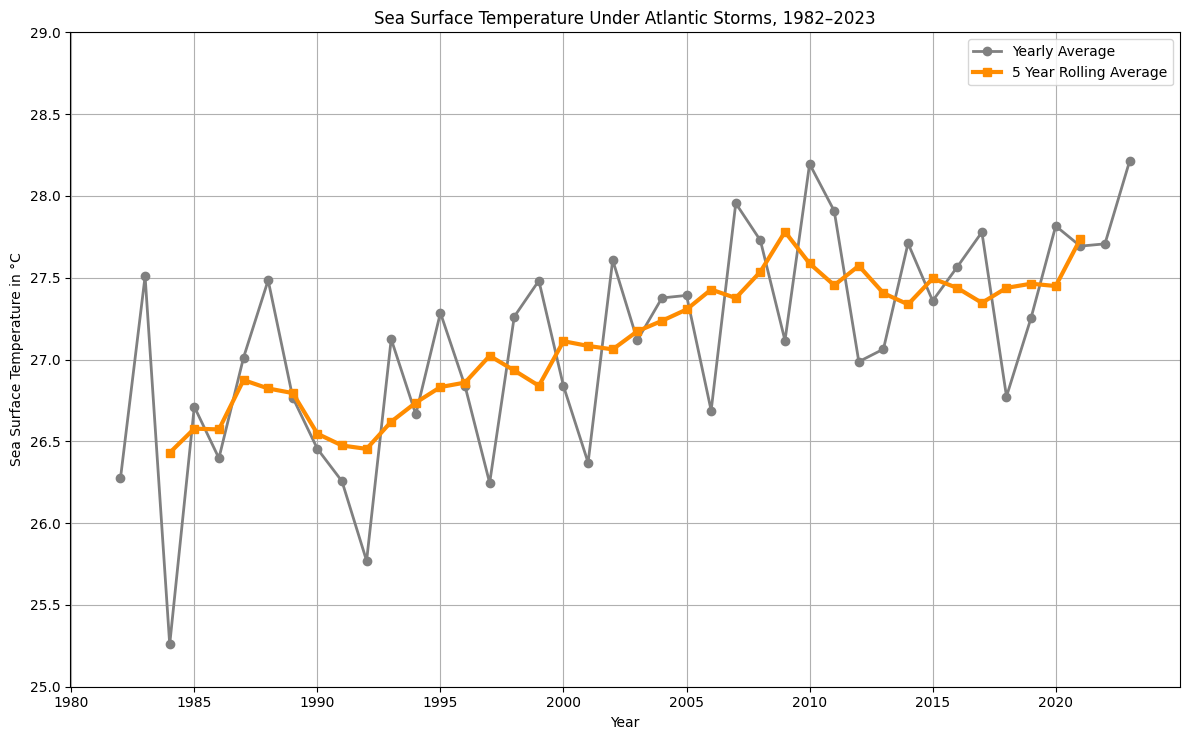


The 5-year rolling average rose from 26.43 °C in 1984 to 27.74 °C in 2021.
That is a change of 1.31 °C.
Limitation: this works like a weighted average. Long-lived storms count more,
even if they are weaker than short, strong storms.


In [ ]:
#Reading csv file:

ship_file = pd.read_csv(SHIPS_DIR, skiprows = [1])
#print(ship_file) # Sanity Check
ship_file = ship_file.dropna() # drops any row with a missing value - this file has none (0 rows removed), but it's kept as a safety check

rows = 0
columns = 0
for i in ship_file['storm_identifier']: # counts rows for 500 rows requirements.
  rows += 1
for j in ship_file:
  columns += 1
print(f'Rows: {rows}, Columns: {columns}')

ship_file['time'] = pd.to_datetime((ship_file['time']).str.replace('Z', ''))
# This line serves its purpose as a conversion of the date and time initially
# given by the csv to a better version of the time. It removed the time being connected by 'Z'
# ex. 1982-06-02T12:00:00Z -> 1982-06-02 12:00:00
#Getting averages for sea temperature

years = []
temp_avg_yearly = []

for year in range(1982,2024): # Data only goes until 2023.
  in_year = (ship_file['time'] >= str(year)) & (ship_file['time'] < str(year+1))
  years.append(year)
  temp_avg_yearly.append(ship_file[in_year]['DSST'].mean())
  # Checking if the time falls in between the year - this for loop calculates the average per year.

# print(temp_avg_yearly) Sanity Check

five_yr_avg = []

for i in range(len(temp_avg_yearly)):
  if i < 2 or i > len(temp_avg_yearly) - 3: # Checking if the iterator has 2 years on either side to calculate 5 year average.
    five_yr_avg.append(np.nan) # plugs it in as Not a number.
  else:
    five_yr_avg.append(sum(temp_avg_yearly[i-2:i+3])/5) # if the iterator is inside the 5 year range, then we do the summation and division of the temps to give the 5 year avg.

def plot_ships(ax):
  ''' This function is used for drawings the ships_file plot on the axes (ax). I decided to use the yearly average and a 5 year rolling average
  of the sea surface temperature when subject to Atlantic Storms. It's a function that allows the plot to be used in a combined figure (infographic)
  '''
  ax.plot(years,temp_avg_yearly,marker = 'o', label = 'Yearly Average', color = 'grey', linewidth = 2) #plots the data requested (x,y ... )
  # the marker creates this circle on the graph which gives it a cleaner and more professional look.
  ax.plot(years,five_yr_avg,marker = 's', label = '5 Year Rolling Average', color = 'darkorange', linewidth = 3) # 's' makes a square, 'o' makes a circle.
  ax.set_xlabel('Year')
  ax.set_xticks(range(1980,2025,5)) # This line gives a 'jump' of 5 years per grid.
  ax.set_ylabel('Sea Surface Temperature in °C')
  ax.set_ylim(25,29)
  ax.set_title('Sea Surface Temperature Under Atlantic Storms, 1982–2023')
  ax.legend()
  ax.grid(True)

fig, ax = plt.subplots(figsize=(12,7.5)) # initiates subplot so that a plot can be added.
plot_ships(ax) # calls the function.
fig.tight_layout() # tight layout refers to making the spacing tight so that nothing gets cut-off.
plt.show()

output_file = PROJECT_DIR + "/images/sea_surface_temp_plot.png"
fig.savefig(output_file)
# These are what we're going to summarize, using the indexes of the five year averages, and then rounding to 2 decimals.
start = round(five_yr_avg[2], 2)
end = round(five_yr_avg[-3], 2)
change = round(five_yr_avg[-3] - five_yr_avg[2], 2)
# Bunch of print statements in order to summarize the data - used f strings.
print()
print(f"The 5-year rolling average rose from {start} °C in {years[2]} to {end} °C in {years[-3]}.")
print(f"That is a change of {change} °C.")
print("Limitation: this works like a weighted average. Long-lived storms count more,")
print("even if they are weaker than short, strong storms.")

# Abdulrahman - Relationship Between Sea-Surface Temperature and Cyclone Intensity

### Sea-Surface Temperature and Cyclone Intensity

I matched the IBTrACS and SHIPS datasets by storm identifier and observation time for 1982–2023. I compared sea-surface temperature with current wind speed and wind change exactly 24 hours later. Red lines show averages within 1°C intervals containing at least 30 observations.

**Findings**
- Current wind speed does not increase consistently with temperature.
- Mean 24-hour wind change shifts from −1.67 knots at 25–26°C to +3.27 knots at 29–30°C, although individual storms vary considerably.
- Limitation: storms contribute repeated observations, and this comparison does not establish that temperature alone causes strengthening.

**Sources:** [NOAA IBTrACS](https://www.ncei.noaa.gov/products/international-best-track-archive) and [NOAA SHIPS](https://erddap.aoml.noaa.gov/hdb/erddap/info/ships_atlantic_7days/index.html).

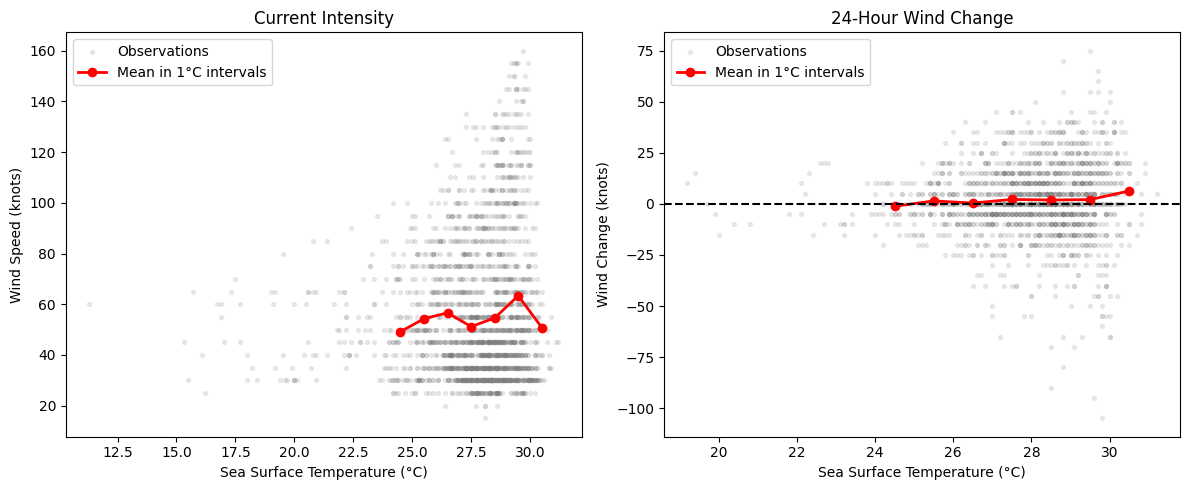

Matched observations: 2200
Distinct storms: 103
Valid 24-hour changes: 1775

Averages use 1°C intervals with at least 30 observations.
NaN means there were too few observations to display an average.
 sst_midpoint_c  wind_count  mean_wind_knots  change_count  mean_wind_change_knots
           11.5           1              NaN             0                     NaN
           12.5           0              NaN             0                     NaN
           13.5           0              NaN             0                     NaN
           14.5           0              NaN             0                     NaN
           15.5           3              NaN             0                     NaN
           16.5           5              NaN             0                     NaN
           17.5           5              NaN             0                     NaN
           18.5           4              NaN             0                     NaN
           19.5          10              NaN         

In [ ]:
# Variables from michael you can use:
# ship_file, years, temp_avg_yearly, five_yr_avg

# Prepare temperateure data without changing existing data table
sst_data = ship_file[["storm_identifier", "time", "DSST"]].copy()
sst_data["storm_identifier"] = sst_data["storm_identifier"].str.strip()
sst_data["time"] = pd.to_datetime(sst_data["time"], errors="coerce", utc=True)
sst_data["DSST"] = pd.to_numeric(sst_data["DSST"], errors="coerce")
sst_data = sst_data.dropna()
sst_data = sst_data[
    (sst_data["storm_identifier"] !="")
    & sst_data["DSST"].between(-2, 40)
].copy()

# Read wind data including the needed identifier to match SHIPS
wind_data = pd.read_csv(
    IBTRACS_FILE,
    skiprows=[1],
    usecols=["USA_ATCF_ID", "ISO_TIME", "USA_STATUS", "USA_WIND", "TRACK_TYPE"],
    low_memory=False
)

wind_data = wind_data.rename(columns={
    "USA_ATCF_ID": "storm_identifier",
    "ISO_TIME": "time",
    "USA_WIND": "wind_knots"
})

wind_data["storm_identifier"] = wind_data["storm_identifier"].str.strip()
wind_data["time"] = pd.to_datetime(wind_data["time"], errors="coerce", utc=True)
wind_data["wind_knots"] = pd.to_numeric(wind_data["wind_knots"], errors="coerce")
wind_data = wind_data.dropna(subset=["storm_identifier", "time", "wind_knots"])

# TD = tropical depression, TS = tropical storm, HU = hurricane
wind_data = wind_data[
    (wind_data["storm_identifier"] !="")
    & (wind_data["TRACK_TYPE"].str.strip() == "main")
    & wind_data["USA_STATUS"].str.strip().isin(["TD", "TS", "HU"])
    & (wind_data["wind_knots"] > 0)
    & wind_data["time"].dt.hour.isin([0, 6, 12, 18])
    & (wind_data["time"].dt.minute == 0)
].copy()

# Match on storm idnetifier and time
match_columns = ["storm_identifier", "time"]

# Keep hurricane records within the temperature dataset's years.
first_year = sst_data["time"].dt.year.min()
last_year = sst_data["time"].dt.year.max()

wind_data = wind_data[
    wind_data["time"].dt.year.between(first_year, last_year)
].copy()

if (sst_data.duplicated(match_columns).any()
        or wind_data.duplicated(match_columns).any()):
    raise ValueError("Duplicate storm/time records found. Check before merging.")

matched_data = pd.merge(
    sst_data,
    wind_data[match_columns + ["wind_knots"]],
    on=match_columns,
    how="inner",
    validate="one_to_one"
)

# Match the same storm exactly 24 hours later
future_wind=wind_data[match_columns + ["wind_knots"]].copy()
future_wind=future_wind.rename(columns={"wind_knots": "wind_24h_later"})
future_wind["time"] = future_wind["time"] - pd.Timedelta(hours=24)

matched_data=pd.merge(
    matched_data, future_wind,
    on=match_columns, how="left", validate="one_to_one"
)
matched_data["wind_change_24h"] = (
    matched_data["wind_24h_later"] - matched_data["wind_knots"]
)
matched_data=matched_data.sort_values(match_columns).reset_index(drop=True)
change_data = matched_data.dropna(subset=["wind_change_24h"])

if len(matched_data) < 500 or len(change_data) == 0:
    raise ValueError("Insufficient matched data. Please check input files")

# Calculate averages with 1 degree Celsius intervals
minimum_count = 30
summary_rows = []

for lower in range(
    int(np.floor(matched_data["DSST"].min())),
    int(np.floor(matched_data["DSST"].max())+1)
):
    interval = matched_data[
        (matched_data["DSST"] >= lower)
        & (matched_data["DSST"] < lower + 1)
    ]
    changes=interval["wind_change_24h"].dropna()
    mean_wind = np.nan
    mean_change = np.nan

    if len(interval) >= minimum_count:
        mean_wind = interval["wind_knots"].mean()
    if len(changes) >= minimum_count:
        mean_change = changes.mean()

    summary_rows.append([
        lower + 0.5, len(interval), mean_wind, len(changes), mean_change
    ])

temperature_summary = pd.DataFrame(summary_rows, columns=[
    "sst_midpoint_c", "wind_count", "mean_wind_knots", "change_count", "mean_wind_change_knots"
])

# Start plotting the observations and averages in two separate graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Graph 1
axes[0].scatter(
    matched_data["DSST"],
    matched_data["wind_knots"],
    label="Observations",
    s=8,
    alpha=0.15,
    color="gray",
)
axes[0].plot(
    temperature_summary["sst_midpoint_c"],
    temperature_summary["mean_wind_knots"],
    label="Mean in 1°C intervals",
    color="red",
    linewidth=2,
    marker="o",
)
axes[0].set_title("Current Intensity")
axes[0].set_xlabel("Sea Surface Temperature (°C)")
axes[0].set_ylabel("Wind Speed (knots)")
axes[0].legend()

# Graph 2
axes[1].scatter(
    change_data["DSST"],
    change_data["wind_change_24h"],
    label="Observations",
    s=8,
    alpha=0.15,
    color="gray",
)
axes[1].plot(
    temperature_summary["sst_midpoint_c"],
    temperature_summary["mean_wind_change_knots"],
    label="Mean in 1°C intervals",
    color="red",
    linewidth=2,
    marker="o",
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("24-Hour Wind Change")
axes[1].set_xlabel("Sea Surface Temperature (°C)")
axes[1].set_ylabel("Wind Change (knots)")
axes[1].legend()

# Ensure labels do not overlap
fig.tight_layout()

# Save image
image_folder = Path(PROJECT_DIR) / "images"
image_folder.mkdir(parents=True, exist_ok=True)
fig.savefig(image_folder / "sst_wind_relationship.png")

plt.show()
plt.close(fig)

# Sample Size and Final Results Display
print("Matched observations:", len(matched_data))
print("Distinct storms:", matched_data["storm_identifier"].nunique())
print("Valid 24-hour changes:", len(change_data))
print("\nAverages use 1°C intervals with at least 30 observations.")
print("NaN means there were too few observations to display an average.")
print(temperature_summary.round(2).to_string(index=False))


# James - Creating interactive graphs
To start this, I did research for what package would be easist, and with the help of Chat GPT ended on plotly. I did want to originally only use matplotlib, however it lacks some of the versatility and does not work well in google colab.
I tried doing a few methods with ipywidgets as AI initially told me just using plotly would not work in a jupyter notebook. Since then I have come to realize it does, so I ditched all the ipywidgetes stuff as it was completelty new to me and would have been a large part AI.

Chat GPT was used to make my hover templates organized properly and neat. I addded functionality that shows hurricane data when hovering over a point with the cursor. A dropdown menu was also added to Chenrons graph to filter the data. Both graphs





In [ ]:
import pandas as pd
import plotly.graph_objects as go




# Directory and data issues will make me end it all so i am re doing this.
PROJECT_DIR = "/content/drive/MyDrive/ENDG_310_G5_2026/Project_01"
IBTRACS_FILE = PROJECT_DIR + "/data/ibtracs.NA.list.v04r01 (1).csv"


# Chenrons data was all done in a function, so I cannot access it nicely
# As a result some of this is copy paste from chenrons code so I can use the data
data = pd.read_csv(
    IBTRACS_FILE,
    skiprows=[1],
    usecols=["SID", "SEASON", "NAME", "ISO_TIME", "USA_WIND", "USA_PRES"],
    low_memory=False,
)

data["USA_WIND"] = pd.to_numeric(data["USA_WIND"], errors="coerce")
data["USA_PRES"] = pd.to_numeric(data["USA_PRES"], errors="coerce")
data["ISO_TIME"] = pd.to_datetime(data["ISO_TIME"], errors="coerce")
data = data.dropna(subset=["USA_WIND", "USA_PRES", "ISO_TIME"])
data = data[(data["USA_WIND"] > 0) & (data["USA_PRES"] > 0)].copy()

category_5 = data[data["USA_WIND"] >= 137].copy()
maximum_wind = data["USA_WIND"].max()
strongest_storms = data[data["USA_WIND"] == maximum_wind].drop_duplicates(subset="SID").copy()

data["wind_bin"] = (data["USA_WIND"] // 10 * 10).astype(int)
averages = data.groupby("wind_bin", as_index=False).agg(
    mean_wind=("USA_WIND", "mean"),
    mean_pressure=("USA_PRES", "mean"),
)

# Gets the storm variables.
def get_storm_stats(df):
    stats = []
    for sid in df["SID"]:
        storm_records = data[data["SID"] == sid]
        stats.append({
            "max_wind": storm_records["USA_WIND"].max(),
            "min_pres": storm_records["USA_PRES"].min(),
            "obs_count": len(storm_records)
        })
    return pd.DataFrame(stats, index=df.index)

cat5_stats = get_storm_stats(category_5)
category_5["max_wind_total"] = cat5_stats["max_wind"]
category_5["min_pres_total"] = cat5_stats["min_pres"]
category_5["obs_count"] = cat5_stats["obs_count"]

strong_stats = get_storm_stats(strongest_storms)
strongest_storms["max_wind_total"] = strong_stats["max_wind"]
strongest_storms["min_pres_total"] = strong_stats["min_pres"]
strongest_storms["obs_count"] = strong_stats["obs_count"]

# Create plotly object
fig1 = go.Figure()

# Adding lines for the first figure
fig1.add_trace(go.Scatter(
    x=data["USA_WIND"], y=data["USA_PRES"],
    mode='markers',
    marker=dict(color='lightgreen', size=4, opacity=0.4),
    name="6-hourly observations",
    hoverinfo="none"
))

fig1.add_trace(go.Scatter(
    x=category_5["USA_WIND"], y=category_5["USA_PRES"],
    mode='markers',
    marker=dict(color='green', size=7, opacity=0.8, line=dict(color='white', width=1)),
    name="Category 5 (137+ knots)",
    customdata=category_5[["NAME", "SEASON", "max_wind_total", "min_pres_total", "obs_count"]],
    # Hover template was done with help of chat so it looked decent.
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Season: %{customdata[1]}<br>"
        "Peak Sustained Wind: %{customdata[2]} knots<br>"
        "Minimum Central Pressure: %{customdata[3]} hPa<br>"
        "Total 6-hourly Observations: %{customdata[4]}<extra></extra>"
    )
))

fig1.add_trace(go.Scatter(
    x=averages["mean_wind"], y=averages["mean_pressure"],
    mode='lines+markers',
    line=dict(color='red', width=3),
    marker=dict(size=6),
    name="Average central pressure",
    hoverinfo="skip"
))


fig1.add_trace(go.Scatter(
    x=strongest_storms["USA_WIND"], y=strongest_storms["USA_PRES"],
    mode='markers',
    marker=dict(color='darkred', symbol='star', size=12, line=dict(color='white', width=1)),
    name="Highest recorded wind speed",
    customdata=strongest_storms[["NAME", "SEASON", "max_wind_total", "min_pres_total", "obs_count"]],
    hovertemplate=( #This was chatgpt
        "<b>%{customdata[0]}</b><br>"
        "Season: %{customdata[1]}<br>"
        "Peak Sustained Wind: %{customdata[2]} knots<br>"
        "Minimum Central Pressure: %{customdata[3]} hPa<br>"
        "Total 6-hourly Observations: %{customdata[4]}<extra></extra>"
    )
))
# Adds vertical line
fig1.add_vline(x=137, line_width=1.5, line_dash="dash", line_color="green")

# Gives axis titles
fig1.update_layout(
    title="North Atlantic Cyclones: Hover over a Category 5 or Peak point for details",
    xaxis_title="Maximum Sustained Wind Speed (knots)",
    yaxis_title="Central Atmospheric Pressure (hPa)",
    template="plotly_white",
    height=500
)
# Creates a dropdown menu for fig1 to filter data.
fig1.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=list([
            dict(label="Show All Data",
                 method="update",
                 args=[{"visible": [True, True, True, True]}]),
            dict(label="Category 5 & Peak",
                 method="update",
                 args=[{"visible": [False, True, False, True]}]),
            dict(label="Average Pressure Trend",
                 method="update",
                 args=[{"visible": [False, False, True, False]}]),
            dict(label="Raw Observations",
                 method="update",
                 args=[{"visible": [True, False, False, False]}])
        ]),
        x=0.05,
        xanchor="left",
        y=1.15,
        yanchor="top"
    )]
)


fig2 = go.Figure()
fig2.add_trace(go.Scatter(
    x=years,
    y=temp_avg_yearly,
    mode='lines+markers',
    name='Yearly Average',
    line=dict(color='grey', width=2),
    marker=dict(symbol='circle', size=6),
    hovertemplate="<b>Year: %{x}</b><br>Yearly Avg: %{y:.2f} °C<extra></extra>"
))

fig2.add_trace(go.Scatter(
    x=years,
    y=five_yr_avg,
    mode='lines+markers',
    name='5 Year Rolling Average',
    line=dict(color='darkorange', width=3),
    marker=dict(symbol='square', size=8),
    hovertemplate="<b>Year: %{x}</b><br>5-Year Avg: %{y:.2f} °C<extra></extra>"
))

fig2.update_layout(
    title='Sea Surface Temperature Under Atlantic Storms, 1982–2023',
    xaxis_title='Year',
    yaxis_title='Sea Surface Temperature in °C',
    yaxis=dict(range=[25, 29]),
    xaxis=dict(tickmode='linear', tick0=1980, dtick=5),
    template="plotly_white",
    hovermode="x unified",  # Shows both values when hovering over a single year
    height=500
)
# Creates range sliders and shows the graphs.
fig1.update_xaxes(rangeslider_visible=True)
fig1.show()
fig2.update_xaxes(rangeslider_visible=True)
fig2.show()